In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import seaborn
import torch
import tensorflow as tf
from torch import nn
from tqdm import tqdm
from torch.nn import functional as F

seaborn.set(style="ticks", context="talk")
# plt.style.use("dark_background")

from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


## Common

In [ ]:
def lowpass(inp, taus, dt=0.01):
  space = torch.tensor([1.0])  # LP
  space = space / space.sum()

  required_steps = int(max(taus) / dt * 5)

  time_line = torch.arange(required_steps) * dt

  kernels = []
  for tau in taus:
    time = torch.exp(-1 * time_line / tau).flip([0])
    time = time / time.sum()
    kernel = space[:, None] * time[None, :]
    kernels.append(kernel)
  kernels = torch.stack(kernels).to(inp.device)

  out = F.conv2d(inp, kernels[:, None, ...], padding=(len(space) // 2, kernel.shape[-1]))

  return out[..., :inp.shape[-1]]

def highpass(inp, tau, dt=0.01):
  return inp - lowpass(inp, tau, dt)

def rect(x,thrld):
    result=x-thrld
    result=result*(result>0)
    result=result+thrld
    return result

class HRBL(nn.Module):
  def __init__(self, tau_hp=0.25, tau_lp=0.05, dt=1.0 / 120.0, offset=.1, DC=0, celltype="T4T5d", TV=1, LV=1, TL=1, LT=0.5, LL=1, block="", HR=False, rect=False, normalize=1):
    super().__init__()

    self.dt = dt
    self.tau_hp = tau_hp
    self.tau_lp = tau_lp
    self.offset = offset
    self.celltype = celltype
    self.TL = TL
    self.LT = LT
    self.LL = LL
    self.TV = TV
    self.LV = LV
    self.block = block
    self.HR = HR
    self.rect = rect
    self.normalize = normalize
    self.DC = DC

  def forward(self, x):

    x_bp = lowpass(highpass(x, [self.tau_hp], self.dt), [self.tau_lp], self.dt)

    interim=x_bp+0.1*x
    L1=rect(interim,0)
    L2=rect(-(interim-0.05),0)

    x_lp_ON = lowpass(x, [self.tau_lp], self.dt)
    x_bp_ON = L1

    x_lp_OFF = lowpass(1-x, [self.tau_lp], self.dt)
    x_bp_OFF = L2

    a_on = x_lp_ON[:, :, 0:-2, :]
    b_on = x_bp_ON[:, :, 1:-1, :]
    c_on = x_lp_ON[:, :, 2:, :]

    a_off = x_lp_OFF[:, :, 0:-2, :]
    b_off = x_bp_OFF[:, :, 1:-1, :]
    c_off = x_lp_OFF[:, :, 2:, :]

    # outT4d = rect(a_on * b_on / (c_on + self.offset),self.offset)
    # outT4c = rect(c_on * b_on / (a_on + self.offset),self.offset)
    # outT5d = rect(a_off * b_off / (c_off + self.offset),self.offset)
    # outT5c = rect(c_off * b_off / (a_off + self.offset),self.offset)
    outT4d = (a_on * b_on / (c_on + self.offset))-self.DC
    outT4c = (c_on * b_on / (a_on + self.offset))-self.DC
    outT5d = (a_off * b_off / (c_off + self.offset))-self.DC
    outT5c = (c_off * b_off / (a_off + self.offset))-self.DC
    if self.HR:
      outT4d = a_on * b_on
      outT4c = b_on * c_on
      outT5d = a_off * b_off
      outT5c = b_off * c_off

    if self.block == "T4c":
      outT4c = 0
    elif self.block == "T4d":
      outT4d = 0
    elif self.block == "T5c":
      outT5c = 0
    elif self.block == "T5d":
      outT5d = 0
    elif self.block == "T4T5c":
      outT4c=0
      outT5c=0
    elif self.block == "T4T5d":
      outT4d=0
      outT5d=0

    outLpi34 = -1 * (outT5c+outT4c) #do we have to scale here?? *0.5
    outLpi43 = -1 * (outT5d+outT4d)

    if self.block == "Lpi34":
      outLpi34=0
    elif self.block == "Lpi43":
      outLpi43=0

    outT4c_inh = outT4c + self.LT * (self.TL*outLpi43 - self.LL*outLpi34)
    outT4d_inh = outT4d + self.LT * (self.TL*outLpi34 - self.LL*outLpi43)
    outT5c_inh = outT5c + self.LT * (self.TL*outLpi43 - self.LL*outLpi34)
    outT5d_inh = outT5d + self.LT * (self.TL*outLpi34 - self.LL*outLpi43)

    # outLpi34_inh = self.TL*(outT4c_inh+outT5c_inh) - self.LL*(outT4d_inh + outT5d_inh)
    # outLpi43_inh = self.TL*(outT4d_inh+outT5d_inh) - self.LL*(outT4c_inh + outT5c_inh)
    outLpi34_inh = self.TL*(outT4c_inh+outT5c_inh) + self.LL*outLpi43
    outLpi43_inh = self.TL*(outT4d_inh+outT5d_inh) + self.LL*outLpi34

    if self.rect == True:
      outT4c_inh = rect(outT4c_inh,-0.1)
      outT4d_inh = rect(outT4d_inh,-0.1)
      outT5c_inh = rect(outT5c_inh,-0.1)
      outT5d_inh = rect(outT5d_inh,-0.1)
      outLpi34_inh = rect(outLpi34_inh,-0.1)
      outLpi43_inh = rect(outLpi43_inh,-0.1)

    if self.celltype == "T4c": #T4T5 with opponent inhibition
      out = outT4c_inh
    elif self.celltype == "T5c":
      out = outT5c_inh
    elif self.celltype == "T4d":
      out = outT4d_inh
    elif self.celltype == "T5d":
      out = outT5d_inh
    elif self.celltype == "T4T5c":
      out = outT4c_inh + outT5c_inh
    elif self.celltype == "T4T5d":
      out = outT4d_inh + outT5d_inh
    elif self.celltype == "Lpi34":
      # out =  self.TL*(outT4c_inh+outT5c_inh) - self.LL*outLpi43_inh
      out =  outLpi34_inh
    elif self.celltype == "Lpi43":
      # out = self.TL*(outT4d_inh+outT5d_inh) - self.LL*outLpi34_inh
      out =  outLpi43_inh
    elif self.celltype == "VS":
      out_T4T5_exc = outT4d_inh+outT5d_inh #- self.LT * (self.TL*outLpi34_inh - self.LL*outLpi43_inh)
      out_Lpi_inh =  -outLpi34_inh + self.LL*outLpi43_inh #sign inversion due to inhibitory Lpi
      out=self.TV * out_T4T5_exc + self.LV * out_Lpi_inh

    if self.normalize:
      # if torch.max(out) > torch.min(out).abs():
      #   out = torch.div(out, torch.max(out))
      # else:
      out = torch.mul(out, self.normalize)
    # if self.rect:
    #   out = rect(out,0)
    return out.sum(2)



## Demo

In [ ]:
class SineGrating:

    @staticmethod
    def get_standard_parameters():
        return {
            "azimuth": 120.0,
            "elevation": 90.0,
            "duration": 5.0,
            "wavelength": 30.0,
            "velocity": 30.0,
            "orientation": 0.0,
            "initial_phase": 0.0,
            "start": 1.0,
            "stop": 4.0,
            "dt": 1.0 / 120.0,
            "ds": 1.0,
        }

    def __init__(self, azimuth, elevation, duration,
                 wavelength, velocity, orientation, initial_phase, start, stop,
                 dt, ds):
        self.az = azimuth
        self.el = elevation
        self.dur = duration
        self.lam = wavelength
        self.vel = velocity
        self.ori = orientation
        self.phase = initial_phase
        self.start = start
        self.stop = stop
        self.dt = dt
        self.ds = ds

    def deg2pix(self, val):
        return int(val / self.ds)

    def t2step(self, val):
        return int(val / self.dt)

    def render(self):
        az = np.arange(self.deg2pix(self.az)) * self.ds
        el = np.arange(self.deg2pix(self.el)) * self.ds
        ori = np.deg2rad(self.ori)
        a, b = np.sin(ori), np.cos(ori)

        time = np.zeros(self.t2step(self.dur))
        start, stop = self.t2step(self.start), self.t2step(self.stop)
        time[start:stop] = self.vel
        time = time.cumsum() * self.dt

        g_el, g_az, g_time = np.meshgrid(el, az, time)  # NOTE: el and az are swapped here
        image = np.sin(2 * np.pi / self.lam * (a * g_el + b * g_az - g_time) + self.phase)

        return image

# class FastDiscretePhi:

#     @staticmethod
#     def get_standard_parameters():
#         return {
#             "azimuth": 120.0,
#             "elevation": 90.0,
#             "duration": 5.0,
#             "wavelength": 30.0,
#             "velocity": 30.0,
#             "initial_phase": 0.0,
#             "start": 1.0,
#             "stop": 4.0,
#             "dt": 1.0 / 120.0,
#             "ds": 1.0,
#         }

#     def __init__(self, wavelength, velocity, duration, start, stop, flip, nd):
#         self.lam = wavelength
#         self.vel = velocity
#         self.duration = duration
#         self.start = start
#         self.stop = stop
#         self.flip = flip
#         self.nd = nd

#     def render(self, recfield, delta_phi, true_dt):

#         n_rec = int(recfield / delta_phi)
#         dt = delta_phi / self.vel

#         t = np.arange(0.0, self.duration, dt)

#         p = np.zeros(len(t))
#         start_, stop_ = int(self.start / dt), int(self.stop / dt)
#         p[start_:stop_] = -1 * self.vel

#         d = np.arange(n_rec) * delta_phi + 20

#         pp, dd = np.meshgrid(dt * p.cumsum(), d)
#         stim = np.sin(2 * np.pi / self.lam * (pp + dd))

#         stim[stim >= 0.0] = 1.0
#         stim[stim < 0.0] = 0.0

#         if self.flip:
#             flipvec = np.ones(len(t))
#             flipvec[start_:stop_:2] = -1.0
#             stim = stim * flipvec

#         if self.nd:
#             stim = np.flipud(stim)

#         repfac = int(dt / true_dt)
#         assert repfac > 1
#         return stim.repeat(repfac, axis=1)


### Frequency tuning

In [ ]:
# detectorT4T5d = HRBL(celltype="T4T5d",LT=0,LL=0).to("cuda")
# detectorT4T5c = HRBL(celltype="T4T5c",LT=0,LL=0).to("cuda")
# detectorT4d   = HRBL(celltype="T4d",LT=0,LL=0).to("cuda")
# detectorT4c   = HRBL(celltype="T4c",LT=0,LL=0).to("cuda")
# detectorT5d   = HRBL(celltype="T5d",LT=0,LL=0).to("cuda")
# detectorT5c   = HRBL(celltype="T5c",LT=0,LL=0).to("cuda")
# detectorLpi43 = HRBL(celltype="Lpi43",LT=0,LL=0).to("cuda")
# detectorLpi34 = HRBL(celltype="Lpi34",LT=0,LL=0).to("cuda")

dt = 1.0 / 120.0

# detectorVS = HRBL(celltype="VS",LT=0, LL=0).to("cuda") #VS without X-inh
X=0.1
detectorT4T5d = HRBL(celltype="T4T5d",LT=0, LL=0,rect=True,DC=X).to("cuda")
detectorT4T5c = HRBL(celltype="T4T5c",LT=0, LL=0,rect=True,DC=X).to("cuda")
detectorT4d   = HRBL(celltype="T4d",LT=0, LL=0,rect=True,DC=X).to("cuda")
detectorT4c   = HRBL(celltype="T4c",LT=0, LL=0,rect=True,DC=X).to("cuda")
detectorT5d   = HRBL(celltype="T5d",LT=0, LL=0,rect=True,DC=X).to("cuda")
detectorT5c   = HRBL(celltype="T5c",LT=0, LL=0,rect=True,DC=X).to("cuda")
detectorLpi43 = HRBL(celltype="Lpi43",LT=0, LL=0,rect=True,DC=X).to("cuda")
detectorLpi34 = HRBL(celltype="Lpi34",LT=0, LL=0,rect=True,DC=X).to("cuda")

detectorVS = HRBL(celltype="VS",TV=4.3, LV=2.1, LT=0, LL=0,rect=True,DC=X,dt=dt).to("cuda") #VS with X-inh

detectorT4T5d_inh = HRBL(celltype="T4T5d",rect=True,DC=X).to("cuda")
detectorT4T5c_inh = HRBL(celltype="T4T5c",rect=True,DC=X).to("cuda")
detectorT4d_inh   = HRBL(celltype="T4d",rect=True,DC=X).to("cuda")
detectorT4c_inh   = HRBL(celltype="T4c",rect=True,DC=X).to("cuda")
detectorT5d_inh   = HRBL(celltype="T5d",rect=True,DC=X).to("cuda")
detectorT5c_inh   = HRBL(celltype="T5c",rect=True,DC=X).to("cuda")
detectorLpi43_inh = HRBL(celltype="Lpi43",rect=True,DC=X).to("cuda")
detectorLpi34_inh = HRBL(celltype="Lpi34",rect=True,DC=X).to("cuda")

detectorVS_inh = HRBL(celltype="VS",rect=True,DC=X,dt=dt).to("cuda") #VS with X-inh

params = SineGrating.get_standard_parameters()
params["azimuth"] = 100.0
params["elevation"] = 5.0
params["wavelength"] = 50.0
params["ds"] = 5.0

meansT4T5d, meansT4T5c, meansT4d, meansT4c, meansT5d, meansT5c, meansLpi43, meansLpi34, meansVS, meansT4T5d_inh, meansT4T5c_inh, meansT4d_inh, meansT4c_inh, meansT5d_inh, meansT5c_inh, meansLpi43_inh, meansLpi34_inh, meansVS_inh, orisT4T5d,orisT4T5c,orisT4d,orisT4c,orisT5d,orisT5c,orisLpi43,orisLpi34,orisVS,orisT4T5d_inh,orisT4T5c_inh,orisT4d_inh,orisT4c_inh,orisT5d_inh,orisT5c_inh,orisLpi43_inh,orisLpi34_inh,orisVS_inh = [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], []

vels = np.linspace(-500, 500, num=1000)
for vel in tqdm(vels):
  params["velocity"] = vel
  sine = SineGrating(**params).render().squeeze() * 0.5 + 0.5
  inp = torch.tensor(sine[None, None, ...]).float().to("cuda")

  for detector, arr in zip((detectorT4T5d,detectorT4T5c,detectorT4d,detectorT4c,detectorT5d,detectorT5c,detectorLpi43,detectorLpi34,detectorVS,detectorT4T5d_inh,detectorT4T5c_inh,detectorT4d_inh,detectorT4c_inh,detectorT5d_inh,detectorT5c_inh,detectorLpi43_inh,detectorLpi34_inh,detectorVS_inh), (meansT4T5d,meansT4T5c,meansT4d,meansT4c,meansT5d,meansT5c,meansLpi43,meansLpi34,meansVS,meansT4T5d_inh,meansT4T5c_inh,meansT4d_inh,meansT4c_inh,meansT5d_inh,meansT5c_inh,meansLpi43_inh,meansLpi34_inh,meansVS_inh)):
    out = detector(inp).squeeze().cpu().numpy()
    mean = out[100:400].mean()
    arr.append(mean)

oris = np.linspace(90, 450, num=1000)
for ori in tqdm(oris):
  params["orientation"] = ori
  params["velocity"] = 50.0
  sine = SineGrating(**params).render().squeeze() * 0.5 + 0.5
  inp_ori = torch.tensor(sine[None, None, ...]).float().to("cuda")

  for detector, arr in zip((detectorT4T5d,detectorT4T5c,detectorT4d,detectorT4c,detectorT5d,detectorT5c,detectorLpi43,detectorLpi34,detectorVS,detectorT4T5d_inh,detectorT4T5c_inh,detectorT4d_inh,detectorT4c_inh,detectorT5d_inh,detectorT5c_inh,detectorLpi43_inh,detectorLpi34_inh,detectorVS_inh), (orisT4T5d,orisT4T5c,orisT4d,orisT4c,orisT5d,orisT5c,orisLpi43,orisLpi34,orisVS,orisT4T5d_inh,orisT4T5c_inh,orisT4d_inh,orisT4c_inh,orisT5d_inh,orisT5c_inh,orisLpi43_inh,orisLpi34_inh,orisVS_inh)):
    out_ori = detector(inp_ori).squeeze().cpu().numpy()
    mean_ori = out_ori[100:400].mean()
    arr.append(mean_ori)

meansT4T5d,meansT4T5c,meansT4d,meansT4c,meansT5d,meansT5c,meansLpi43,meansLpi34,meansVS,meansT4T5d_inh,meansT4T5c_inh,meansT4d_inh,meansT4c_inh,meansT5d_inh,meansT5c_inh, meansLpi43_inh,meansLpi34_inh,meansVS_inh = np.array(meansT4T5d),np.array(meansT4T5c),np.array(meansT4d),np.array(meansT4c),np.array(meansT5d),np.array(meansT5c), np.array(meansLpi43),np.array(meansLpi34), np.array(meansVS),np.array(meansT4T5d_inh),np.array(meansT4T5c_inh),np.array(meansT4d_inh),np.array(meansT4c_inh),np.array(meansT5d_inh),np.array(meansT5c_inh), np.array(meansLpi43_inh),np.array(meansLpi34_inh),np.array(meansVS_inh)
orisT4T5d,orisT4T5c,orisT4d,orisT4c,orisT5d,orisT5c,orisLpi43,orisLpi34,orisVS,orisT4T5d_inh,orisT4T5c_inh,orisT4d_inh,orisT4c_inh,orisT5d_inh,orisT5c_inh, orisLpi43_inh,orisLpi34_inh,orisVS_inh = np.array(orisT4T5d),np.array(orisT4T5c),np.array(orisT4d),np.array(orisT4c),np.array(orisT5d),np.array(orisT5c), np.array(orisLpi43),np.array(orisLpi34), np.array(orisVS),np.array(orisT4T5d_inh),np.array(orisT4T5c_inh),np.array(orisT4d_inh),np.array(orisT4c_inh),np.array(orisT5d_inh),np.array(orisT5c_inh), np.array(orisLpi43_inh),np.array(orisLpi34_inh),np.array(orisVS_inh)

100%|██████████| 1000/1000 [00:38<00:00, 26.21it/s]


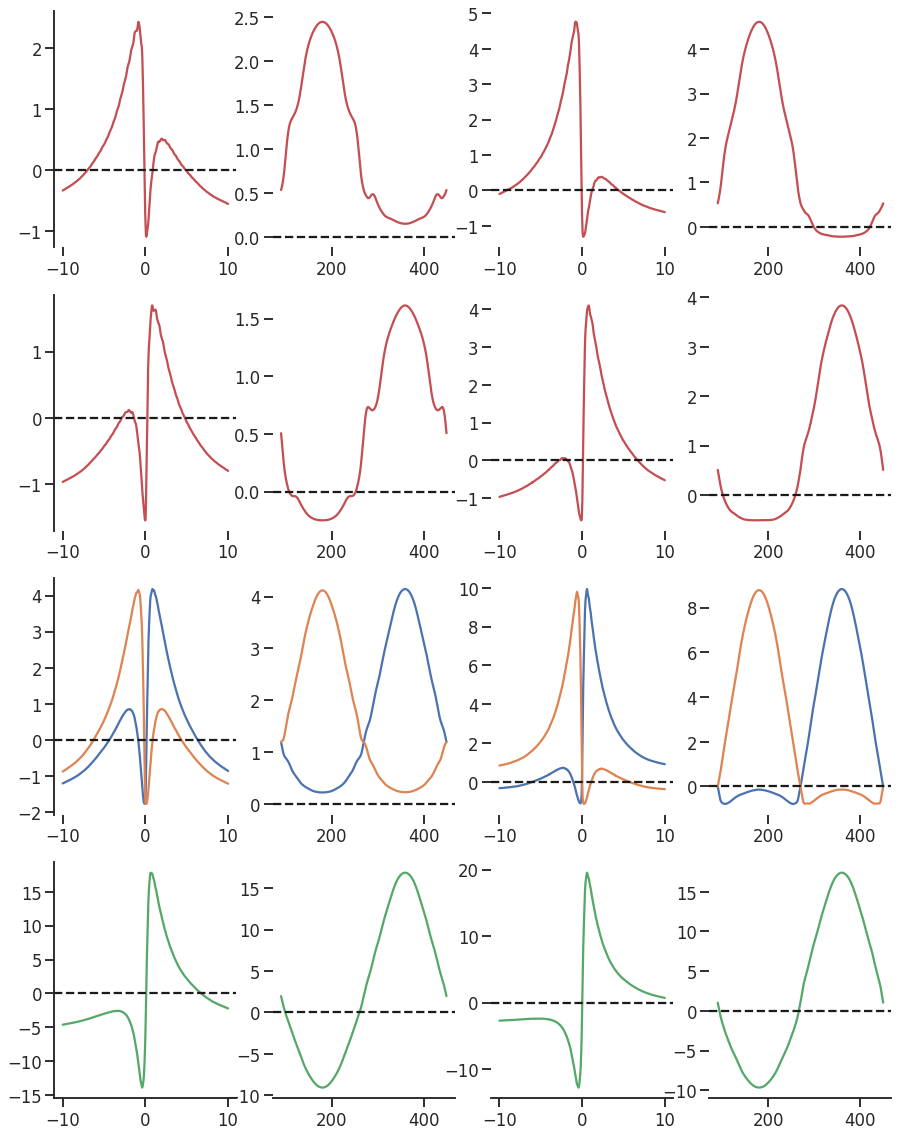

In [ ]:
import time
timestr = time.strftime("%Y%m%d-%H%M%S")
# meansT4d /= meansT4d.max()
# meansT4c /= meansT4c.max()
# meansT5d /= meansT5d.max()
# meansT5c /= meansT5c.max()
# meansT4d_inh /= meansT4d_inh.max()
# meansT4c_inh /= meansT4c_inh.max()
# meansT5d_inh /= meansT5d_inh.max()
# meansT5c_inh /= meansT5c_inh.max()
# meansLpi43 /= meansLpi43.max()
# meansLpi34 /= meansLpi34.max()
# meansLpi43_inh /= meansLpi43_inh.max()
# meansLpi34_inh /= meansLpi34_inh.max()
# meansVS /= meansVS.max()
# meansVS_inh /= meansVS_inh.max()

# orisT4d /= orisT4d.max()
# orisT4c /= orisT4c.max()
# orisT5d /= orisT5d.max()
# orisT5c /= orisT5c.max()
# orisT4d_inh /= orisT4d_inh.max()
# orisT4c_inh /= orisT4c_inh.max()
# orisT5d_inh /= orisT5d_inh.max()
# orisT5c_inh /= orisT5c_inh.max()
# orisLpi43 /= orisLpi43.max()
# orisLpi34 /= orisLpi34.max()
# orisLpi43_inh /= orisLpi43_inh.max()
# orisLpi34_inh /= orisLpi34_inh.max()
# orisVS /= orisVS.max()
# orisVS_inh /= orisVS_inh.max()

fig, axs = plt.subplots(4, 4, figsize=(15,20))
# plt.plot(vels / 50.0, meansT4T5c_inh, label="T4T5c_inh")
# plt.plot(vels / 50.0, meansT4T5d_inh, label="T4T5d_inh")
# plt.plot(vels / 50.0, meansT4T5c, label="T4T5c")
# plt.plot(vels / 50.0, meansT4T5d, label="T4T5d")
# axs[0,0].plot(vels / 50.0, meansT4d, label="T4d", color='r')
axs[0,0].plot(vels / 50.0, meansT4c, label="T4c", color='r')
# axs[1,0].plot(vels / 50.0, meansT5d, label="T5d", color='r')
axs[1,0].plot(vels / 50.0, meansT5d, label="T5d", color='r')
# axs[1,2].plot(vels / 50.0, meansT5d_inh, label="T5d_inh", color='r')
# axs[0,2].plot(vels / 50.0, meansT4d_inh, label="T4d_inh", color='r')
axs[1,2].plot(vels / 50.0, meansT5d_inh, label="T5d_inh", color='r')
axs[0,2].plot(vels / 50.0, meansT4c_inh, label="T4c_inh", color='r')

axs[2,0].plot(vels / 50.0, meansLpi43, label="Lpi43")
axs[2,0].plot(vels / 50.0, meansLpi34, label="Lpi34")
axs[2,2].plot(vels / 50.0, meansLpi43_inh, label="Lpi43_inh")
axs[2,2].plot(vels / 50.0, meansLpi34_inh, label="Lpi34_inh")

axs[3,2].plot(vels / 50.0, meansVS_inh, label="VS_inh", color='g')
axs[3,0].plot(vels / 50.0, meansVS, label="VS", color='g')


# plt.plot(oris, orisT4T5c_inh, label="T4T5c_inh")
# plt.plot(oris, orisT4T5d_inh, label="T4T5d_inh")
# plt.plot(oris, orisT4T5c, label="T4T5c")
# plt.plot(oris, orisT4T5d, label="T4T5d")

# axs[0,1].plot(oris, orisT4d, label="T4d", color='r')
axs[0,1].plot(oris, orisT4c, label="T4c", color='r')
# axs[1,1].plot(oris, orisT5d, label="T5d", color='r')
axs[1,1].plot(oris, orisT5d, label="T5d", color='r')

# axs[1,3].plot(oris, orisT5d_inh, label="T5d_inh", color='r')
# axs[0,3].plot(oris, orisT4d_inh, label="T4d_inh", color='r')
axs[1,3].plot(oris, orisT5d_inh, label="T5d_inh", color='r')
axs[0,3].plot(oris, orisT4c_inh, label="T4c_inh", color='r')

axs[2,1].plot(oris, orisLpi43, label="Lpi43")
axs[2,1].plot(oris, orisLpi34, label="Lpi34")
axs[2,3].plot(oris, orisLpi43_inh, label="Lpi43_inh")
axs[2,3].plot(oris, orisLpi34_inh, label="Lpi34_inh")

axs[3,3].plot(oris, orisVS_inh, label="VS_inh", color='g')
axs[3,1].plot(oris, orisVS, label="VS", color='g')

for c in axs:
   for ax in c:
    ax.axhline(0, ls="--", color='k')

# plt.xlabel("Temporal frequency (Hz)")
# plt.ylabel("Response (a.u.)")

for ax in axs.flat:#
    # ax.set_yticks([])
    # ax.set_xticks([])
    seaborn.despine(bottom=not ax.is_last_row(), left=not ax.is_first_col(), ax=ax)

plt.savefig(
  "/content/drive/My Drive/Colab Notebooks/Simulations/"+timestr+"_intro_detector_freqtuning.pdf",
  dpi=300,
  bbox_inches="tight",
)

## Optimize stimulus for one model

In [ ]:
class ExperimentOne(nn.Module):
  def __init__(self,
    detector1,
    loss_profile,
    stimulus_length=5.0,
    batch_size=16,
    num_detectors=20,
    dt=1.0 / 120.0,
    initial_noise=0.2,
    add_noise=0.1,
    l2_loss=0.0,
    l1_loss=0.0,
    var_loss=0.0,
  ):

    super().__init__()

    self.detector1 = detector1
    self.dt = dt
    self.batch_size = batch_size
    self.add_noise = add_noise
    self.loss_profile = loss_profile
    self.l2_loss = l2_loss
    self.l1_loss = l1_loss
    self.var_loss = var_loss

    nt = int(stimulus_length / dt)
    target = torch.rand(1, 1, num_detectors, nt)
    target = (target - 0.5) * initial_noise + 0.5
    self.target = nn.Parameter(target)

  def forward(self):
    target = self.target.repeat([self.batch_size, 1, 1, 1])
    target += self.add_noise * torch.rand_like(target)
    target = torch.clamp(target, 0, 1.0)        #0 is minimum and 1 is maximum in target

    out = self.detector1(target).squeeze()

    # Calculate loss:

    overall_loss = 0.0
    last_up_to = 0

    for up_to_s, weight in zip(*self.loss_profile):
      up_to_n = int(up_to_s / self.dt)

      if weight == 0:
        overall_loss += out[:, last_up_to:up_to_n].abs().sum()  #trying to include the negative outcomes and removing .abs()
      else:
        overall_loss += out[:, last_up_to:up_to_n].sum() * weight

      last_up_to = up_to_n

    # L1/L2:
    l2_loss = self.target.pow(2.0).sum()
    l1_loss = self.target.abs().sum()
    var_loss = self.target.var()

    return overall_loss + self.l2_loss * l2_loss + self.l1_loss * l1_loss + self.var_loss * var_loss

In [ ]:
# torch.autograd.set_detect_anomaly(True) #use this if you get funny error warnings


##########################################################################################################################################
#### IMPORTANT don´t forget to change it here!!!!!########################################################################################
detector1 = detectorVS_inh#################################################################################################################
detector2 = detectorVS#############################################################################################################
#### For which detector you want to find the optimal stimulus???##########################################################################
### Detector1´s output will be optimized to it´s strongest and weakest response###########################################################


exp = ExperimentOne(
  detector1,
  loss_profile=[(0.5, 1.5, 2.0, 3.0, 3.5), (0, -1, 0, 1, 0)],
  stimulus_length=3.5,
  batch_size=16,
  num_detectors=20,
  dt=1.0 / 120.0,
  initial_noise=0.2,
  add_noise=0.05,
).to("cuda")

optimizer = torch.optim.SGD(exp.parameters(), lr=0.0001)

losses = []
images = []

for idx in tqdm(range(10000)):
  optimizer.zero_grad()
  loss = exp()
  loss.backward()
  optimizer.step()

  losses.append(loss.item())

  if idx % 50 == 0:
    gen_stim = exp.target.cpu().detach().numpy().squeeze()
    images.append(gen_stim)

images = np.stack(images)


100%|██████████| 10000/10000 [00:57<00:00, 173.50it/s]


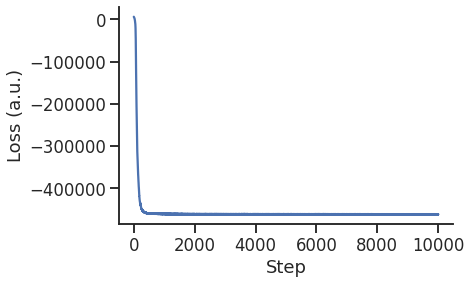

In [ ]:
cellt=detector1.celltype
ll=detector1.LL
lt=detector1.LT

plt.plot(losses)
# plt.yticks([0, -1000, -2000, -3000, -4000, -5000, -6000])
plt.ylabel("Loss (a.u.)")
plt.xlabel("Step")

seaborn.despine(ax=plt.gca())

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt)+"LL"+str(ll)+"LT"+str(lt)+"intro_loss_curve.jpg", dpi=300, bbox_inches="tight")

In [ ]:
video_path = "/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt)+"LL"+str(ll)+"LT"+str(lt)+"intro_optim_vid.avi"
size = (640, 320)
video = cv2.VideoWriter(video_path, cv2.VideoWriter_fourcc(*"MJPG"), 30, size, True)

for idx in range(images.shape[0]):
  image = images[idx, ...]
  image = np.clip(image, 0., 1.) * 255.0
  image = image.astype("uint8")
  image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
  image = cv2.resize(image, (640, 320), interpolation=cv2.INTER_AREA)

  video.write(image)

video.release()

In [ ]:
video_path = "/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt)+"LL"+str(ll)+"LT"+str(lt)+"intro_stimulus.avi"
size = (640, 640)
video = cv2.VideoWriter(video_path, cv2.VideoWriter_fourcc(*"MJPG"), 30, size, True)

for idx in range(images.shape[-1]):
  image = images[-1, :, idx:idx+1].T
  image = np.clip(image, 0., 1.) * 255.0
  image = image.astype("uint8")
  image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
  image = cv2.resize(image, size, interpolation=cv2.INTER_AREA)

  video.write(image)

video.release()

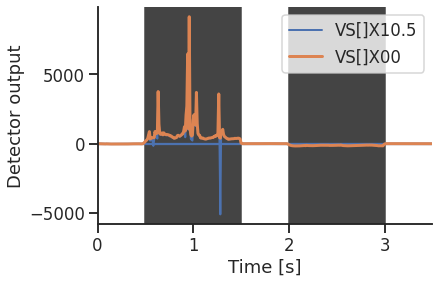

In [ ]:
gen_stim = exp.target.cpu().detach()

d1, d2 = detector1, detector2 ##### Compare it to another Model and insert it here

out1 = d1(gen_stim)
out2 = d2(gen_stim)

t = np.arange(420) * 1.0 / 120.0

plt.plot(t, out1.numpy()[0, 0, :], lw=2, label=f"{detector1.celltype}[{detector1.block}]X{detector1.LL}{detector1.LT}")
plt.plot(t, out2.numpy()[0, 0, :], lw=3, label=f"{detector2.celltype}[{detector2.block}]X{detector2.LL}{detector2.LT}")

plt.legend()

plt.axhline(0, zorder=0)
plt.axvspan(0.5, 1.5, color="#444444", zorder=0)
plt.axvspan(2.0, 3.0, color="#444444", zorder=0)

plt.xlim([0, 3.5])
# plt.yticks([])
plt.ylabel("Detector output")
plt.xlabel("Time [s]")

seaborn.despine(ax=plt.gca())

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt)+"LL"+str(ll)+"LT"+str(lt)+"intro_detector_response.jpg", dpi=300, bbox_inches="tight")

## Optimize difference

In [ ]:
timestr = time.strftime("%Y%m%d-%H%M%S")
class ExperimentTwo(nn.Module):
  def __init__(self,
    detector1,
    detector2,
    stimulus_length=5.0,
    batch_size=64,
    silence_period=1.0,
    num_detectors=21,
    dt=1.0 / 120.0,
    initial_noise=0.2,
    add_noise=0.1,
  ):

    super().__init__()

    self.detector1 = detector1
    self.detector2 = detector2
    self.dt = dt
    self.batch_size = batch_size
    self.silence_period = int(silence_period / self.dt)
    self.add_noise = add_noise

    nt = int(stimulus_length / dt)
    target = torch.rand(1, 1, num_detectors, nt)
    target = (target - 0.5) * initial_noise + 0.5
    self.target = nn.Parameter(target)

  def forward(self):
    target = self.target.repeat([self.batch_size, 1, 1, 1])
    target += self.add_noise * torch.rand_like(target)
    target = torch.clamp(target, 0, 1.0)

    target_nd = torch.flip(target, [0,2])

    out_target1 = self.detector1(target).squeeze()
    out_target1_nd = self.detector1(target_nd).squeeze()
    out_target2 = self.detector2(target).squeeze()
    out_target2_nd = self.detector2(target_nd).squeeze()

    out1 = out_target1 #/ mean_sine1 # out1=out_target1                 out_target comparison if you don´t want to "normalize" to the sine-wave response of the detectors
    out2 = out_target2 #/ mean_sine2 # out2=out_target2
    out1_nd = out_target1_nd
    out2_nd = out_target2_nd

    # Calculate loss:
    ns = self.silence_period
    loss_ns = out1[:, :ns].abs().sum()
    loss_ns += out1[:, -ns:].abs().sum()
    loss_ns += out2[:, :ns].abs().sum()
    loss_ns += out2[:, -ns:].abs().sum()

    loss_contrastive = -1 * (out1[:, ns:-ns].sum() - out2[:, ns:-ns].sum())
    loss_contrastive_nd = -1 * (out1_nd[:, ns:-ns].sum() - out2_nd[:, ns:-ns].sum())
    # loss_contrastive_detector1 = -1 * (out1[:, ns:-ns].sum() - out1_nd[:, ns:-ns].sum())
    # loss_contrastive_detector2 = -1 * (out2[:, ns:-ns].sum() - out2_nd[:, ns:-ns].sum())
    # loss_zero = out2[:, ns:-ns].abs().sum()

    # Drive one to max, one to zero or Minus1??:
    loss1 = 1 * out1[:, ns:-ns].abs().sum()         ####remove abs add a - in front of the 1
    loss1_nd = 1 * out1_nd[:, ns:-ns].abs().sum()
    loss2 = 1 * out2[:, ns:-ns].abs().sum()         ####add - in front of 1
    loss2_nd = 1 * out2_nd[:, ns:-ns].abs().sum()
    #loss through correlation of the two outputs
    combined = torch.cat((out1[:, ns:-ns], out2[:, ns:-ns]), 0)
    combined_nd = torch.cat((out1_nd[:, ns:-ns], out2_nd[:, ns:-ns]),0)
    # n_start = 100  # Use this to target specific area of time series
    # n_end = 500
    # combined = torch.stack([out1[:, ns:-ns], out2[:, ns:-ns]])  # We need to combine them for corrcoef
    # corr = torch.corrcoef(combined)

    corr = torch.corrcoef(combined)[0, 1]  # corrcoef produces a covariance matrix; we take one off-diagonal element for the Pearson correlation
    corr_nd = torch.corrcoef(combined_nd)[0, 1]
    loss_corr = torch.abs(corr)  # To drive correlation to zero, we minimize the absolute correlation
    loss_corr_nd = torch.abs(corr_nd)
    return (loss_corr * loss_corr_weight) + (loss_corr_nd * loss_corr_nd_weight) + (loss_ns * loss_ns_weight) + (loss_contrastive * loss_contrastive_weight) + (loss_contrastive_nd * loss_contrastive_nd_weight) + (loss2 * loss2_zero_weight) + (loss2_nd * loss2_nd_zero_weight) + (loss1 * loss1_max_weight) + (loss1_nd * loss1_nd_max_weight) #+ (loss_contrastive_detector1 * loss_contrastive_weight)+ (loss_contrastive_detector2 * loss_contrastive_weight)

In [ ]:
def run_experiment_two(d1, d2, dt, lr, steps):

  exp = ExperimentTwo(
    d1,
    d2,
    stimulus_length=5,
    batch_size=128,
    silence_period=1,
    num_detectors=21,
    dt=dt,
    initial_noise=1,
    add_noise=0.2,
  ).to("cuda")

  optimizer = torch.optim.SGD(exp.parameters(), lr=lr)

  losses = []

  for idx in tqdm(range(steps)):
    optimizer.zero_grad()
    loss = exp()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

  losses = np.array(losses)
  stim_np = np.clip(exp.target.cpu().detach().numpy().squeeze(), 0., 1.)
  stim_torch = torch.clamp(exp.target.cpu().detach(), 0., 1.)
  stim_torch_pd = torch.flip(stim_torch, [0,2])
  stim_np_pd = stim_torch_pd.cpu().detach().numpy().squeeze()

  return stim_torch, stim_torch_pd, stim_np, stim_np_pd, losses

## Model 1 vs. Model 2



In [ ]:
dt = 1.0 / 120.0

cellt1=detector1.celltype
ll1=detector1.LL
lt1=detector1.LT

cellt2=detector2.celltype
ll2=detector2.LL
lt2=detector2.LT

params = SineGrating.get_standard_parameters()
params["azimuth"] = 100.0
params["elevation"] = 5.0
params["wavelength"] = 30.0
params["velocity"] = 30.0
params["ds"] = 5.0
params["dt"] = 1.0 / 120.0
params["duration"] = 5.0
params["start"] = 1
params["stop"] = 4

sine = SineGrating(**params).render().squeeze() * 0.5 + 0.5
# sine = np.where(sine >= 0.5, 1.0, 0.0)

inp = torch.tensor(sine[None, None, ...]).float().to("cuda")
sqw_np = inp.cpu().detach().numpy().squeeze()
inp_nd = torch.flip(inp, [0,2])
sqw_nd_np = inp_nd.cpu().detach().numpy().squeeze()

out_sine1 =  detector1(inp).squeeze() #ominous -1 again appearing I removed it
out_sine1_np = out_sine1.cpu().detach().numpy().squeeze()
out_sine1_nd = detector1(inp_nd).squeeze() #ominous -1 again appearing I removed it
out_sine1_nd_np = out_sine1_nd.cpu().detach().numpy().squeeze()
mean_sine1 = out_sine1[100:400].mean()
mean_sine1_nd = out_sine1_nd[100:400].mean()
mean_sine1_np = out_sine1_np[100:400].mean()
mean_sine1_nd_np = out_sine1_nd_np[100:400].mean()

out_sine2 =  detector2(inp).squeeze() #ominous -1 again appearing I removed it
out_sine2_np = out_sine2.cpu().detach().numpy().squeeze()
out_sine2_nd = detector2(inp_nd).squeeze() #ominous -1 again appearing I removed it
out_sine2_nd_np = out_sine2_nd.cpu().detach().numpy().squeeze()
mean_sine2 = out_sine2[100:400].mean()
mean_sine2_nd = out_sine2_nd[100:400].mean()
mean_sine2_np = out_sine2_np[100:400].mean()
mean_sine2_nd_np = out_sine2_nd_np[100:400].mean()

t = np.arange(600) * dt
plt.figure()
plt.plot(t, out_sine1_np , label=f"{detector1.celltype}[{detector1.block}]X{detector1.LL}{detector1.LT}",color="blue")
plt.plot(t, out_sine1_nd_np , label=None,color="blue")
plt.plot(t, out_sine2_np , label=f"{detector2.celltype}[{detector2.block}]X{detector2.LL}{detector2.LT}",color="red")
plt.plot(t, out_sine2_nd_np , label=None,color="red")


plt.axvspan(1, 4, color="#444444",zorder=0)
plt.axhline(0.0, zorder=0, ls="--")
plt.legend(loc=(0.8, 0.8))
plt.xlabel("Time (s)")
plt.ylabel("Detector response")


seaborn.despine(ax=plt.gca())

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/Gridsearch/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"discrim_stimulus_refresp_nd.jpg", dpi=300, bbox_inches="tight")
# detector1 = detectorT4T5c_inh
# detector2 = detectorT4T5c

# corr_steps = np.arange(0.1,0.3,.1)
# contr_steps = np.arange(0.15,0.18,.005)
# ns_steps=np.arange(0.1,0.3,.1)
gridsteps = np.arange(0.04,0.24,.05)
# for corr_weight in corr_steps:
for loss1_weight_nd in gridsteps:
    for loss2_weight_nd in gridsteps:
        for loss1_weight in gridsteps:
            for loss2_weight in gridsteps:

                    loss_corr_weight = 0.2#corr_weight
                    loss_corr_nd_weight = 0.2#corr_weight

                    loss_contrastive_weight = 0.165#contrastive_weight
                    loss_contrastive_nd_weight = 0.165#contrastive_weight

                    loss_ns_weight = 0.45#ns_weight

                    loss1_max_weight = loss1_weight
                    loss1_nd_max_weight = loss1_weight_nd

                    loss2_zero_weight = loss2_weight
                    loss2_nd_zero_weight = loss2_weight_nd

                    timestr = time.strftime("%Y%m%d-%H%M%S")

                    stim_torch, stim_torch_pd, stim_np, stim_np_pd, losses = run_experiment_two(detector1, detector2, dt=dt, lr=0.0001, steps=1000)

                    # video_path = "/content/drive/MyDrive/Colab Notebooks/Simulations/Gridsearch/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"corr_w"+str(loss_corr_weight)+"ns_w"+str(loss_ns_weight)+"contr_w"+str(loss_contrastive_weight)+"det1_max_w"+str(loss1_max_weight)+"det2_zero_w"+str(loss2_zero_weight)+"discrim_stimulus.avi"
                    # size = (640, 640)
                    # # fourcc = cv2.VideoWriter_fourcc(*"mp4v") #codec
                    # video = cv2.VideoWriter(video_path, cv2.VideoWriter_fourcc(*"MJPG"), 100, size, True)

                    # images = stim_np

                    # for idx in range(images.shape[-1]):
                    #   image = images[:, idx:idx+1].T
                    #   image = np.clip(image, 0., 1.) * 255.0
                    #   image = image.astype("uint8")
                    #   image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
                    #   image = cv2.resize(image, size, interpolation=cv2.INTER_AREA)

                    #   video.write(image)

                    # video.release()

                    # plt.figure(figsize=(10, 5))

                    # plt.pcolor(np.arange(600) * dt, np.arange(22), stim_np, cmap="gray", vmin=0.0, vmax=1.0)
                    # plt.xlabel("Time (s)")
                    # plt.ylabel("Photoreceptors")

                    # plt.axvline(1, color="red")
                    # plt.axvline(4, color="red")

                    # plt.xticks(np.arange(11) * 0.5)
                    # plt.yticks()

                    # plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/Gridsearch/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"corr_w"+str(loss_corr_weight)+"ns_w"+str(loss_ns_weight)+"contr_w"+str(loss_contrastive_weight)+"det1_max_w"+str(loss1_max_weight)+"det2_zero_w"+str(loss2_zero_weight)+"discrim_stimulus_2d_nd.jpg", dpi=300, bbox_inches="tight")

                    # plt.figure(figsize=(10, 5))

                    # plt.pcolor(np.arange(600) * dt, np.arange(22), stim_np_pd, cmap="gray", vmin=0.0, vmax=1.0)
                    # plt.xlabel("Time (s)")
                    # plt.ylabel("Photoreceptors")

                    # plt.axvline(1, color="red")
                    # plt.axvline(4, color="red")

                    # plt.xticks(np.arange(11) * 0.5)
                    # plt.yticks()

                    # plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/Gridsearch/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"corr_w"+str(loss_corr_weight)+"ns_w"+str(loss_ns_weight)+"contr_w"+str(loss_contrastive_weight)+"det1_max_w"+str(loss1_max_weight)+"det2_zero_w"+str(loss2_zero_weight)+"discrim_stimulus_2d_pd.jpg", dpi=300, bbox_inches="tight")

                    # f, axes = plt.subplots(2,2,figsize=(10, 5))

                    fig, axs = plt.subplots(2, 2, sharey='row',
                          gridspec_kw={'hspace': 0, 'wspace': 0},figsize=(10, 5))
                    (ax1, ax2), (ax3, ax4) = axs

                    ax1.pcolormesh(stim_np, cmap="gray")
                    ax2.pcolormesh(stim_np_pd, cmap="gray")
                    # plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/Gridsearch/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"corr_w"+str(loss_corr_weight)+"ns_w"+str(loss_ns_weight)+"contr_w"+str(loss_contrastive_weight)+"det1_max_w"+str(loss1_max_weight)+"det2_zero_w"+str(loss2_zero_weight)+"discrim_stimulus_2d_nd.jpg", dpi=300, bbox_inches="tight")
                    # plt.tight_layout()

                    out1_discrim = detector1(stim_torch) #/ out_sine1
                    out1_discrim_np = out1_discrim.cpu().detach().numpy().squeeze()
                    out2_discrim = detector2(stim_torch) #/ out_sine2
                    out2_discrim_np = out2_discrim.cpu().detach().numpy().squeeze()

                    out1_discrim_pd = detector1(stim_torch_pd) #/ out_sine1_nd                  #watch out because of pd/nd nomenclature that was stupid
                    out1_discrim_pd_np = out1_discrim_pd.cpu().detach().numpy().squeeze()
                    out2_discrim_pd = detector2(stim_torch_pd) #/ out_sine2_nd
                    out2_discrim_pd_np = out2_discrim_pd.cpu().detach().numpy().squeeze()

                    t = np.arange(600) * 1.0 / 120.0
                    # plt.figure(figsize=(10, 5))
                    ax3.plot(t, out1_discrim_np, label=f"{detector1.celltype}[{detector1.block}]X{detector1.LL}{detector1.LT}",color="blue")
                    ax3.plot(t, out2_discrim_np, label=f"{detector2.celltype}[{detector2.block}]X{detector2.LL}{detector2.LT}",color="red")
                    # plt.axvspan(1, 4, color="#444444",zorder=0)
                    ax3.axhline(0.0, zorder=0, ls="--")
                    # ax3.yaxis.tick_right()
                    ax3.set_xlim(0.1, 5)

                    # plt.xlabel("Time (s)")

                    # plt.yticks([0., 0.5, 1.0])
                    # plt.ylabel("Detector response")
                    ax4.plot(t, out1_discrim_pd_np, label=None,color="blue")
                    ax4.plot(t, out2_discrim_pd_np, label=None,color="red")
                    # plt.axvspan(1, 4, color="#444444",zorder=0)
                    ax4.axhline(0.0, zorder=0, ls="--")
                    # plt.legend(loc=(0.5, 0.8))
                    ax4.set_xlabel("Time (s)")
                    # ax4.yaxis.tick_left()
                    ax4.set_xlim(0.1, 5)
                    # plt.yticks([0., 0.5, 1.0])
                    # plt.ylabel("Detector response")
                    # plt.ylim([-1, 1])

                    seaborn.despine(ax=plt.gca())

                    plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/Gridsearch/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"corr_w"+str(loss_corr_weight)+"ns_w"+str(loss_ns_weight)+"contr_w"+str(loss_contrastive_weight)+"det1_max_w"+str(loss1_max_weight)+"det2_zero_w"+str(loss2_zero_weight)+"discrim_stimulus_resp.jpg", dpi=300, bbox_inches="tight")
                    np.savez("/content/drive/MyDrive/Colab Notebooks/Simulations/Gridsearch/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"discrim", stim_np=stim_np,stim_np_pd=stim_np_pd,out1_discrim=out1_discrim,out2_discrim=out2_discrim,out1_discrim_pd=out1_discrim_pd,out2_discrim_pd=out2_discrim_pd,out_sine1_np=out_sine1_np,out_sine1_nd_np=out_sine1_nd_np,out_sine2_np=out_sine2_np,out_sine2_nd_np=out_sine2_nd_np)# plt.tight_layout()


100%|██████████| 1000/1000 [01:14<00:00, 13.36it/s]
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:146: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
100%|██████████| 1000/1000 [01:15<00:00, 13.24it/s]
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:146: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
100%|██████████| 1000/1000 [01:14<00:00, 13.37it/s]
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:146: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplo

In [ ]:
youtuvideo_path = "/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"corr_w"+str(loss_corr_weight)+"ns_w"+str(loss_ns_weight)+"contr_w"+str(loss_contrastive_weight)+"det1_max_w"+str(loss1_max_weight)+"det2_zero_w"+str(loss2_zero_weight)+"discrim_stimulus.avi"
size = (640, 640)
# fourcc = cv2.VideoWriter_fourcc(*"mp4v") #codec
video = cv2.VideoWriter(video_path, cv2.VideoWriter_fourcc(*"MJPG"), 100, size, True)

images = stim_np

for idx in range(images.shape[-1]):
  image = images[:, idx:idx+1].T
  image = np.clip(image, 0., 1.) * 255.0
  image = image.astype("uint8")
  image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
  image = cv2.resize(image, size, interpolation=cv2.INTER_AREA)

  video.write(image)

video.release()

In [ ]:
plt.figure(figsize=(10, 5))

plt.pcolor(np.arange(600) * dt, np.arange(22), stim_np, cmap="gray", vmin=0.0, vmax=1.0)
plt.xlabel("Time (s)")
plt.ylabel("Photoreceptors")

plt.axvline(1, color="red")
plt.axvline(4, color="red")

plt.xticks(np.arange(11) * 0.5)
plt.yticks()

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"corr_w"+str(loss_corr_weight)+"ns_w"+str(loss_ns_weight)+"contr_w"+str(loss_contrastive_weight)+"det1_max_w"+str(loss1_max_weight)+"det2_zero_w"+str(loss2_zero_weight)+"discrim_stimulus_2d_nd.jpg", dpi=300, bbox_inches="tight")

In [ ]:
plt.figure(figsize=(10, 5))

plt.pcolor(np.arange(600) * dt, np.arange(22), stim_np_pd, cmap="gray", vmin=0.0, vmax=1.0)
plt.xlabel("Time (s)")
plt.ylabel("Photoreceptors")

plt.axvline(1, color="red")
plt.axvline(4, color="red")

plt.xticks(np.arange(11) * 0.5)
plt.yticks()

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"corr_w"+str(loss_corr_weight)+"ns_w"+str(loss_ns_weight)+"contr_w"+str(loss_contrastive_weight)+"det1_max_w"+str(loss1_max_weight)+"det2_zero_w"+str(loss2_zero_weight)+"discrim_stimulus_2d_pd.jpg", dpi=300, bbox_inches="tight")

In [ ]:
out1_discrim = detector1(stim_torch)
out1_discrim_np = out1_discrim.cpu().detach().numpy().squeeze()
out2_discrim = detector2(stim_torch)
out2_discrim_np = out2_discrim.cpu().detach().numpy().squeeze()

t = np.arange(600) * 1.0 / 120.0

plt.plot(t, out1_discrim_np, label=f"{detector1.celltype}[{detector1.block}]X{detector1.LL}{detector1.LT}")
plt.plot(t, out2_discrim_np, label=f"{detector2.celltype}[{detector2.block}]X{detector2.LL}{detector2.LT}")
plt.axvspan(1, 4, color="#444444",zorder=0)
plt.axhline(0.0, zorder=0, ls="--")
plt.legend(loc=(0.5, 0.8))
plt.xlabel("Time (s)")
# plt.yticks([0., 0.5, 1.0])
plt.ylabel("Detector response")
# plt.ylim([-1, 1])

seaborn.despine(ax=plt.gca())

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"discrim_stimulus_resp.jpg", dpi=300, bbox_inches="tight")

In [ ]:
out1_discrim_pd = detector1(stim_torch_pd)
out1_discrim_pd_np = out1_discrim_pd.cpu().detach().numpy().squeeze()

out2_discrim_pd = detector2(stim_torch_pd)
out2_discrim_pd_np = out2_discrim_pd.cpu().detach().numpy().squeeze()

t = np.arange(600) * dt

plt.plot(t, out1_discrim_pd.numpy()[0, 0, :], label=f"{detector1.celltype}[{detector1.block}]X{detector1.LL}{detector1.LT}")
plt.plot(t, out2_discrim_pd.numpy()[0, 0, :], label=f"{detector2.celltype}[{detector2.block}]X{detector2.LL}{detector2.LT}")
plt.axvspan(1, 4, color="#444444",zorder=0)
plt.axhline(0.0, zorder=0, ls="--")
plt.legend(loc=(0.5, 0.8))
plt.xlabel("Time (s)")
# plt.yticks([0., 0.5, 1.0])
plt.ylabel("Detector response")
# plt.ylim([-1, 1])

seaborn.despine(ax=plt.gca())

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"discrim_stimulus_resp_pd.jpg", dpi=300, bbox_inches="tight")

In [ ]:
out1_norm = detector1(stim_torch) / out_sine1#this compares it directly to the sine wave response moving downward
out1_norm_np = out1_norm.cpu().detach().numpy().squeeze() #/ out_sine1_np
out2_norm = detector2(stim_torch) / out_sine2
out2_norm_np = out2_norm.cpu().detach().numpy().squeeze() #/ out_sine1_np
t = np.arange(600) * dt

plt.plot(t, out1_norm_np, label=f"{detector1.celltype}[{detector1.block}]X{detector1.LL}{detector1.LT}")
plt.plot(t, out2_norm_np, label=f"{detector2.celltype}[{detector2.block}]X{detector2.LL}{detector2.LT}")
plt.axvspan(1, 4, color="#444444",zorder=0)
plt.axhline(0.0, zorder=0, ls="--")
plt.legend(loc=(0.5, 0.8))
plt.xlabel("Time (s)")
# plt.yticks([0., 0.5, 1.0])
plt.ylabel("SQ normalized Detector response")
# plt.ylim([-1, 1])

seaborn.despine(ax=plt.gca())

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"discrim_stimulus_resp_norm.jpg", dpi=300, bbox_inches="tight")

In [ ]:
out1_norm_nd = detector1(stim_torch_pd) / out_sine1_nd#this compares it directly to the sine wave response moving downward
out1_norm_nd_np = out1_norm_nd.cpu().detach().numpy().squeeze()
out2_norm_nd = detector2(stim_torch_pd) / out_sine2_nd
out2_norm_nd_np = out2_norm.cpu().detach().numpy().squeeze()
t = np.arange(600) * dt

plt.plot(t, out1_norm_nd_np, label=f"{detector1.celltype}[{detector1.block}]X{detector1.LL}{detector1.LT}")
plt.plot(t, out2_norm_nd_np, label=f"{detector2.celltype}[{detector2.block}]X{detector2.LL}{detector2.LT}")
plt.axvspan(1, 4, color="#444444",zorder=0)
plt.axhline(0.0, zorder=0, ls="--")
plt.legend(loc=(0.5, 0.8))
plt.xlabel("Time (s)")
# plt.yticks([0., 0.5, 1.0])
plt.ylabel("SQ normalized Detector response")
# plt.ylim([-1, 1])

seaborn.despine(ax=plt.gca())

plt.savefig("/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"discrim_stimulus_resp_pd_norm.jpg", dpi=300, bbox_inches="tight")

In [ ]:
plt.matshow(sqw_nd_np, cmap="gray", vmin=0.0, vmax=1.0, aspect=10.0)

In [ ]:
np.savez("/content/drive/MyDrive/Colab Notebooks/Simulations/"+timestr+str(cellt1)+"LL"+str(ll1)+"LT"+str(lt1)+"VERSUS"+str(cellt2)+"LL"+str(ll2)+"LT"+str(lt2)+"discrim", stim_np=stim_np,stim_np_pd=stim_np_pd,out1_discrim=out1_discrim,out2_discrim=out2_discrim,out1_discrim_pd=out1_discrim_pd,out2_discrim_pd=out2_discrim_pd,out1_sq=out1_sq,out2_sq=out2_sq)

In [ ]:
# xt=np.load("/content/drive/MyDrive/Colab Notebooks/Simulations/20220707-135645VSLL0.9LT0.7VERSUSVSLL0LT0discrim.npz")

In [ ]:
# xt.files
# xt['stim_np'].shape

In [ ]:
!pip install hexalattice

In [ ]:
import torch
from mpl_toolkits.mplot3d import axes3d
from hexalattice.hexalattice import *

In [ ]:
degrees = 100;
io_angle = 5; #interommatidial angle in deg
visual_field = np.arange(degrees/io_angle); #2D visual field for x and y
# fig, (h_ax, ax1) = plt.subplots(1,2)

hex_grid1, h_ax = create_hex_grid(nx=20,
                              ny=20,
                              rotate_deg=0,
                              min_diam=io_angle,
                              crop_circ=20,
                              do_plot=True)

angle = torch.linspace( 0 , 10, 360, requires_grad=True )

radius_VS = 20
radius_exc = 2
radius_inh = 3

x_VS = radius_VS * torch.cos( angle )
y_VS = radius_VS * torch.sin( angle )
x_exc = radius_exc * torch.cos( angle )
y_exc = radius_exc * torch.sin( angle )
x_inh = radius_inh * torch.cos( angle )
y_inh = radius_inh * torch.sin( angle )

h_ax.plot(x_VS.detach().numpy(), y_VS.detach().numpy(), color='g' )
h_ax.plot(x_exc.detach().numpy(), y_exc.detach().numpy(),color='b' )
h_ax.plot(x_inh.detach().numpy(), y_inh.detach().numpy(),color='r' )

# for xpos in np.arange(len(hex_grid1)):
#   for ypos in np.arange(len(hex_grid1)):
#     h_ax.plot(x_exc.detach().numpy()+hex_grid1[xpos,0], y_exc.detach().numpy()+hex_grid1[ypos,1],color='b' )
#     h_ax.plot(x_inh.detach().numpy()+hex_grid1[xpos,0], y_inh.detach().numpy()+hex_grid1[ypos,1],color='r' )

h_ax.set_aspect( 1 )

plt.show()